
# Practical No-03: Autoencoder and Variational Autoencoder for Image Reconstruction



Student Information
- **College Name:** MIT Academy of Engineering, Alandi, Pune
- **Student Name:** Shreya Dattaram Bhosale
- **PRN Number:** 202502110010
- **Class**: T.Y. B.Tech
- **Batch:** A3
- **Course:** Generative AI Lab
- **Department:** CSE (AI & ML)
- **Practical No.:** 03
- **Date of Submission:** 29/09/2026

## 1. Objective

- To implement an **Autoencoder** for image reconstruction.
- To implement a **Variational Autoencoder (VAE)** for image reconstruction and generation.
- To understand the encoder, latent representation, and decoder components.
- To visualize reconstructed images produced by both models.
- To generate new images using the latent space of the VAE.
- To compare the reconstruction quality and generation capability of the Autoencoder and VAE.

## 2. Problem Statement

Build an Autoencoder and a Variational Autoencoder (VAE) using the EEEMNIST Letters dataset for image reconstruction and generation.

The Autoencoder should learn a compact latent representation of input images and reconstruct them as accurately as possible. The VAE should learn a probabilistic latent representation that can be sampled to reconstruct existing images and generate new letter-like images.

The performance of both models will be compared using reconstruction loss and visual analysis of reconstructed and generated images.

## 3. Dataset

### EMNIST Letters Dataset

EMNIST Letters contains grayscale images of handwritten English alphabet letters.

- Image size: **28 × 28 pixels**
- Number of classes: **26 letters (A–Z)**
- Pixel values: **0 to 255**, normalized to **0 to 1**
- Training subset used in this notebook: **30,000 images**
- Testing subset used in this notebook: **5,000 images**
- Labels are not needed for reconstruction because each model learns to reproduce its input image.

Unlike the original MNIST dataset, which contains handwritten digits, EMNIST Letters contains handwritten alphabet characters. The input image is used as the target output for both the Autoencoder and VAE.


## 4. Data Preprocessing

The following preprocessing steps are performed:

1. Load the EMNIST Letters dataset using TensorFlow Datasets.
2. Select a training subset of 30,000 images and a test subset of 5,000 images.
3. Convert pixel values from the range 0–255 to 0–1.
4. Convert images to `float32`.
5. Ensure each image has shape `(28, 28, 1)`.
6. Orient the image axes for upright display.
7. Use each input image as its own target during reconstruction training.


In [6]:
# Install TensorFlow Datasets if it is not already installed
%pip install -q tensorflow-datasets


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("TensorFlow Datasets version:", tfds.__version__)


TensorFlow version: 2.21.0
NumPy version: 2.1.3
TensorFlow Datasets version: 4.9.10


In [8]:
%pip install -q importlib_resources

# Load EMNIST Letters dataset from TensorFlow Datasets
train_ds, test_ds = tfds.load(
    "emnist/letters",
    split=["train", "test"],
    as_supervised=True
)

# Use subsets to keep the practical manageable on a standard notebook runtime
train_pairs = list(tfds.as_numpy(train_ds.take(30000)))
test_pairs = list(tfds.as_numpy(test_ds.take(5000)))

x_train = np.stack([image for image, label in train_pairs]).astype("float32") / 255.0
x_test = np.stack([image for image, label in test_pairs]).astype("float32") / 255.0

# EMNIST images are stored with axes that may appear transposed; transpose for upright display
x_train = np.transpose(x_train, (0, 2, 1, 3))
x_test = np.transpose(x_test, (0, 2, 1, 3))

print("Dataset: EMNIST Letters")
print("Training subset shape:", x_train.shape)
print("Testing subset shape :", x_test.shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())


Dataset: EMNIST Letters
Training subset shape: (30000, 28, 28, 1)
Testing subset shape : (5000, 28, 28, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


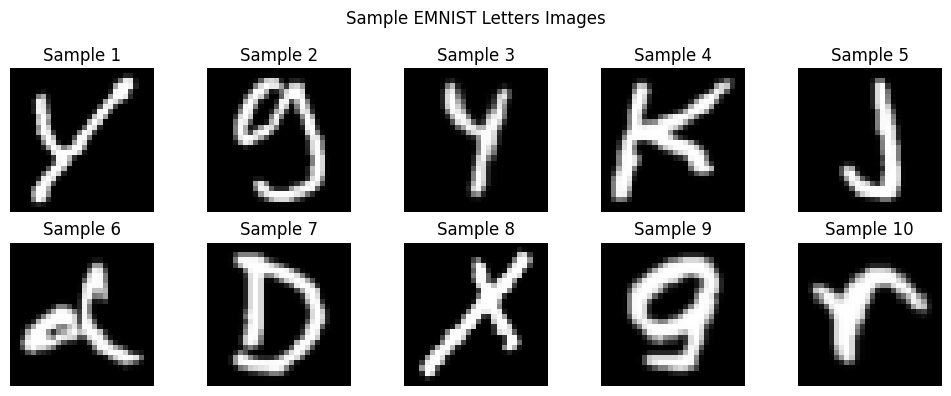

In [9]:
# Display sample EMNIST letter images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].squeeze(), cmap="gray")
    plt.axis("off")
    plt.title(f"Sample {i + 1}")

plt.suptitle("Sample EMNIST Letters Images")
plt.tight_layout()
plt.show()


## 5. Methodology

The practical is divided into two stages.

### Stage 1: Autoencoder

The Autoencoder consists of:

**Input Image → Encoder → Latent Representation → Decoder → Reconstructed Image**

The encoder compresses the input image into a lower-dimensional representation. The decoder uses this representation to reconstruct the original image. The model is trained by minimizing reconstruction error.

### Stage 2: Variational Autoencoder

The VAE follows:

**Input Image → Encoder → Mean and Log Variance → Sampling → Decoder → Reconstructed Image**

Unlike a standard Autoencoder, the VAE learns a probability distribution in the latent space. A latent vector is sampled using the reparameterization trick. The VAE is trained using both reconstruction loss and KL-divergence loss.

### Performance Evaluation

The models are compared using:

- Reconstruction loss
- Original versus reconstructed images
- Quality of reconstructed images
- VAE-generated images from randomly sampled latent vectors
- Training-loss curves

# Part A — Autoencoder

## 6. Autoencoder Architecture

The Autoencoder used in this practical is a convolutional Autoencoder.

### Encoder

The encoder:
- Accepts a 28 × 28 × 1 image.
- Uses convolutional layers to extract image features.
- Uses downsampling to reduce spatial dimensions.
- Produces a compact latent representation.

### Decoder

The decoder:
- Takes the latent representation.
- Uses upsampling and convolutional layers.
- Reconstructs the image back to 28 × 28 × 1.

A **sigmoid activation** is used in the output layer because the image pixels are normalized to the range 0–1.

In [10]:
# Build the convolutional Autoencoder
latent_dim = 32

encoder_inputs = keras.Input(shape=(28, 28, 1), name="encoder_input")

x = layers.Conv2D(32, 3, activation="relu", padding="same", strides=2)(encoder_inputs)
x = layers.Conv2D(64, 3, activation="relu", padding="same", strides=2)(x)
x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)
latent = layers.Dense(latent_dim, name="latent_vector")(x)

encoder = keras.Model(encoder_inputs, latent, name="autoencoder_encoder")

latent_inputs = keras.Input(shape=(latent_dim,), name="latent_input")

x = layers.Dense(7 * 7 * 64, activation="relu")(latent_inputs)
x = layers.Reshape((7, 7, 64))(x)
x = layers.Conv2DTranspose(64, 3, activation="relu", padding="same", strides=2)(x)
x = layers.Conv2DTranspose(32, 3, activation="relu", padding="same", strides=2)(x)
decoder_outputs = layers.Conv2D(1, 3, activation="sigmoid", padding="same")(x)

decoder = keras.Model(latent_inputs, decoder_outputs, name="autoencoder_decoder")

autoencoder_inputs = keras.Input(shape=(28, 28, 1), name="autoencoder_input")
encoded = encoder(autoencoder_inputs)
decoded = decoder(encoded)

autoencoder = keras.Model(autoencoder_inputs, decoded, name="autoencoder")

autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ autoencoder_encoder             │ (None, 32)             │       424,480 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ autoencoder_decoder             │ (None, 28, 28, 1)      │       159,169 │
│ (Functional)                    │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 583,649 (2.23 MB)

 Trainable params: 583,649 (2.23 MB)

 Non-trainable params: 0 (0.00 B)

## 7. Autoencoder Training

The Autoencoder is trained using **Mean Squared Error (MSE)** as the reconstruction loss.

For an input image `x` and reconstructed image `x̂`:

**MSE = mean((x − x̂)²)**

The Adam optimizer is used to update the model parameters during training.

In [11]:
# Train the Autoencoder
AE_EPOCHS = 10
BATCH_SIZE = 128

ae_history = autoencoder.fit(
    x_train,
    x_train,
    epochs=AE_EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    validation_data=(x_test, x_test),
    verbose=1
)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 88s 359ms/step - loss: 0.0651 - val_loss: 0.0223
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 71s 304ms/step - loss: 0.0152 - val_loss: 0.0115
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 71s 302ms/step - loss: 0.0095 - val_loss: 0.0089
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 70s 298ms/step - loss: 0.0077 - val_loss: 0.0076
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 70s 300ms/step - loss: 0.0067 - val_loss: 0.0069
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 81s 295ms/step - loss: 0.0061 - val_loss: 0.0065
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 89s 325ms/step - loss: 0.0058 - val_loss: 0.0062
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 71s 300ms/step - loss: 0.0055 - val_loss: 0.0060
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 80s 291ms/step - loss: 0.0052 - val_loss: 0.0058
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 70s 297ms/step - loss: 0.0050 - val_loss: 0.0056


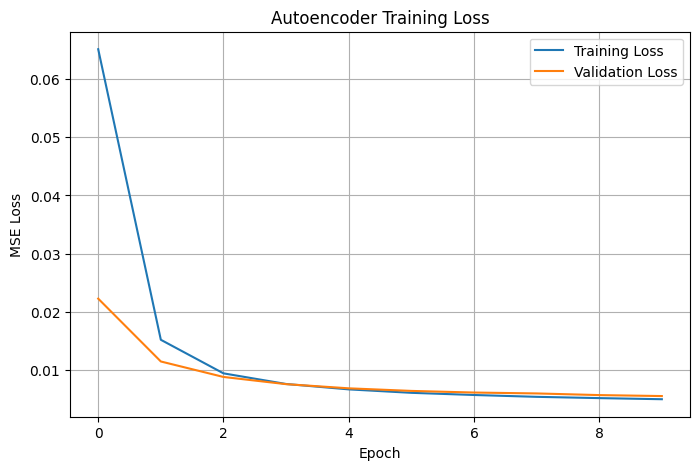

In [12]:
# Plot Autoencoder training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(ae_history.history["loss"], label="Training Loss")
plt.plot(ae_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training Loss")
plt.legend()
plt.grid(True)
plt.show()

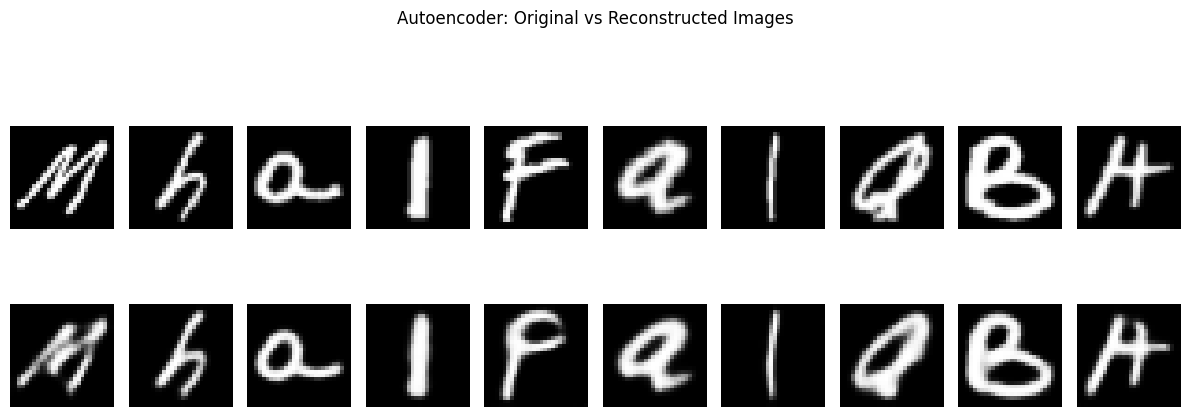

In [13]:
# Reconstruct test images using Autoencoder
ae_reconstructed = autoencoder.predict(x_test[:10], verbose=0)

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Original", fontsize=10)

    plt.subplot(2, 10, i + 11)
    plt.imshow(ae_reconstructed[i].squeeze(), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("AE", fontsize=10)

plt.suptitle("Autoencoder: Original vs Reconstructed Images")
plt.tight_layout()
plt.show()

In [14]:
# Calculate Autoencoder test reconstruction loss
ae_test_loss = autoencoder.evaluate(x_test, x_test, verbose=0)

print(f"Autoencoder Test Reconstruction MSE: {ae_test_loss:.6f}")

Autoencoder Test Reconstruction MSE: 0.005591


# Part B — Variational Autoencoder (VAE)

## 8. VAE Architecture

The Variational Autoencoder differs from the standard Autoencoder because the encoder does not produce one fixed latent vector directly.

Instead, the encoder produces:

- **μ (mean)**
- **log(σ²) (log variance)**

A latent vector is then sampled using the reparameterization trick:

**z = μ + exp(0.5 × log(σ²)) × ε**

where:

**ε ~ N(0, I)**

This makes the latent space continuous and suitable for generating new images.

In [15]:
# Sampling layer for the VAE
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

In [16]:
# VAE encoder
vae_latent_dim = 16

vae_encoder_inputs = keras.Input(shape=(28, 28, 1), name="vae_encoder_input")

x = layers.Conv2D(32, 3, activation="relu", strides=2, padding="same")(vae_encoder_inputs)
x = layers.Conv2D(64, 3, activation="relu", strides=2, padding="same")(x)
x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)

z_mean = layers.Dense(vae_latent_dim, name="z_mean")(x)
z_log_var = layers.Dense(vae_latent_dim, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])

vae_encoder = keras.Model(
    vae_encoder_inputs,
    [z_mean, z_log_var, z],
    name="vae_encoder"
)

vae_encoder.summary()

Model: "vae_encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ vae_encoder_input   │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 14, 14,    │        320 │ vae_encoder_inpu… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 7, 7, 64)  │     18,496 │ conv2d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 3136)      │          0 │ conv2d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │    401,536 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 16)        │      2,064 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 16)        │      2,064 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 16)        │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 424,480 (1.62 MB)

 Trainable params: 424,480 (1.62 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
# VAE decoder
vae_latent_inputs = keras.Input(shape=(vae_latent_dim,), name="vae_latent_input")

x = layers.Dense(7 * 7 * 64, activation="relu")(vae_latent_inputs)
x = layers.Reshape((7, 7, 64))(x)
x = layers.Conv2DTranspose(64, 3, activation="relu", strides=2, padding="same")(x)
x = layers.Conv2DTranspose(32, 3, activation="relu", strides=2, padding="same")(x)
vae_decoder_outputs = layers.Conv2D(1, 3, activation="sigmoid", padding="same")(x)

vae_decoder = keras.Model(
    vae_latent_inputs,
    vae_decoder_outputs,
    name="vae_decoder"
)

vae_decoder.summary()

Model: "vae_decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vae_latent_input (InputLayer)   │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3136)           │        53,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 108,993 (425.75 KB)

 Trainable params: 108,993 (425.75 KB)

 Non-trainable params: 0 (0.00 B)

## 9. VAE Loss Function

The VAE uses two loss components.

### 1. Reconstruction Loss

This measures how closely the reconstructed image matches the original image.

**Reconstruction Loss = sum of binary cross-entropy over image pixels**

### 2. KL-Divergence Loss

KL-divergence regularizes the learned latent distribution so that it stays close to a standard normal distribution.

**KL Loss = -0.5 × Σ(1 + log(σ²) − μ² − σ²)**

### Total Loss

**Total VAE Loss = Reconstruction Loss + KL Loss**

The two losses together encourage the VAE to reconstruct images while maintaining a structured and sampleable latent space.

In [18]:
# Custom VAE model with reconstruction + KL divergence loss
class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(
            name="reconstruction_loss"
        )
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def train_step(self, data):
        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data, training=True)
            reconstruction = self.decoder(z, training=True)

            # Binary cross-entropy per pixel, then sum over image dimensions
            bce = keras.backend.binary_crossentropy(data, reconstruction)
            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(bce, axis=(1, 2))
            )

            # KL divergence
            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var),
                    axis=1
                )
            )

            total_loss = reconstruction_loss + kl_loss

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

    def test_step(self, data):
        if isinstance(data, tuple):
            data = data[0]

        z_mean, z_log_var, z = self.encoder(data, training=False)
        reconstruction = self.decoder(z, training=False)

        bce = keras.backend.binary_crossentropy(data, reconstruction)
        reconstruction_loss = tf.reduce_mean(
            tf.reduce_sum(bce, axis=(1, 2))
        )

        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(
                1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var),
                axis=1
            )
        )

        total_loss = reconstruction_loss + kl_loss

        return {
            "loss": total_loss,
            "reconstruction_loss": reconstruction_loss,
            "kl_loss": kl_loss,
        }

    def call(self, inputs):
        z_mean, z_log_var, z = self.encoder(inputs)
        return self.decoder(z)

In [19]:
# Create and compile the VAE
vae = VAE(vae_encoder, vae_decoder, name="vae")
vae.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001))

vae.summary()

Model: "vae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vae_encoder (Functional)        │ ((None, 16), (None,    │       424,480 │
│                                 │ 16), (None, 16))       │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vae_decoder (Functional)        │ (None, 28, 28, 1)      │       108,993 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 533,473 (2.04 MB)

 Trainable params: 533,473 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

## 10. VAE Training

The VAE is trained on the EEEMNIST Letters training images.

During training:

1. The encoder calculates `z_mean` and `z_log_var`.
2. The sampling layer generates `z`.
3. The decoder reconstructs the image.
4. Reconstruction loss measures image reconstruction quality.
5. KL-divergence regularizes the latent distribution.
6. The total loss is minimized using the Adam optimizer.

In [20]:
# Train the VAE
VAE_EPOCHS = 10

vae_history = vae.fit(
    x_train,
    epochs=VAE_EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    validation_data=(x_test, None),
    verbose=1
)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 77s 314ms/step - kl_loss: 8.4290 - loss: 276.5019 - reconstruction_loss: 268.0730 - val_kl_loss: 12.9281 - val_loss: 198.6032 - val_reconstruction_loss: 185.6751
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 69s 295ms/step - kl_loss: 19.9731 - loss: 194.1853 - reconstruction_loss: 174.2122 - val_kl_loss: 20.6200 - val_loss: 176.9772 - val_reconstruction_loss: 156.3572
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 85s 309ms/step - kl_loss: 23.8385 - loss: 168.3731 - reconstruction_loss: 144.5345 - val_kl_loss: 20.9850 - val_loss: 155.9893 - val_reconstruction_loss: 135.0043
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 70s 299ms/step - kl_loss: 24.7724 - loss: 161.6369 - reconstruction_loss: 136.8646 - val_kl_loss: 21.7456 - val_loss: 162.5673 - val_reconstruction_loss: 140.8216
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 71s 301ms/step - kl_loss: 25.1822 - loss: 158.3855 - reconstruction_loss: 133.2033 - val_kl_loss: 21.9033 - val_loss: 152.6823 - val_reconstruction_l

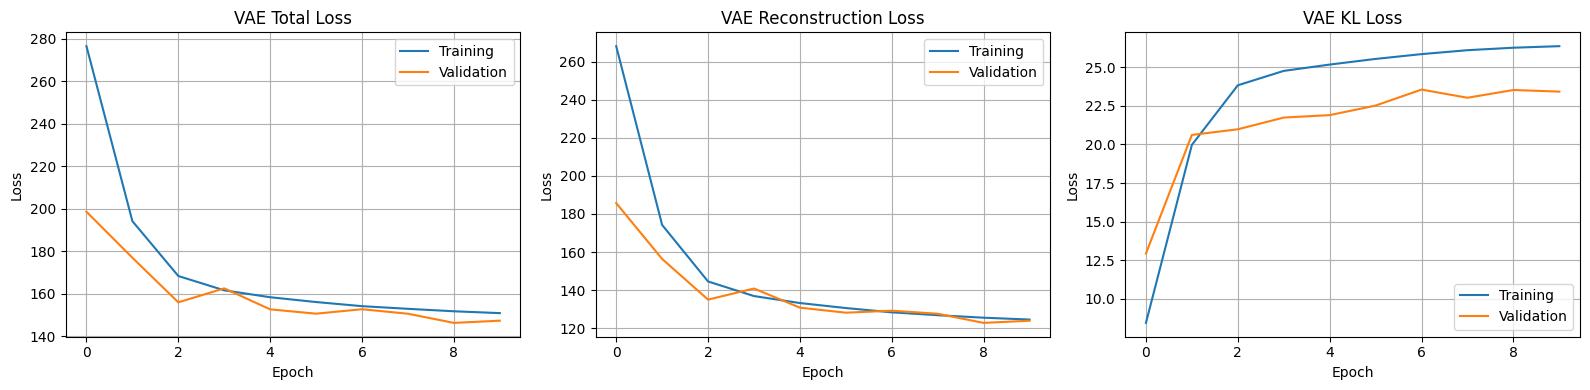

In [21]:
# Plot VAE losses
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(vae_history.history["loss"], label="Training")
axes[0].plot(vae_history.history["val_loss"], label="Validation")
axes[0].set_title("VAE Total Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(vae_history.history["reconstruction_loss"], label="Training")
axes[1].plot(vae_history.history["val_reconstruction_loss"], label="Validation")
axes[1].set_title("VAE Reconstruction Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

axes[2].plot(vae_history.history["kl_loss"], label="Training")
axes[2].plot(vae_history.history["val_kl_loss"], label="Validation")
axes[2].set_title("VAE KL Loss")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

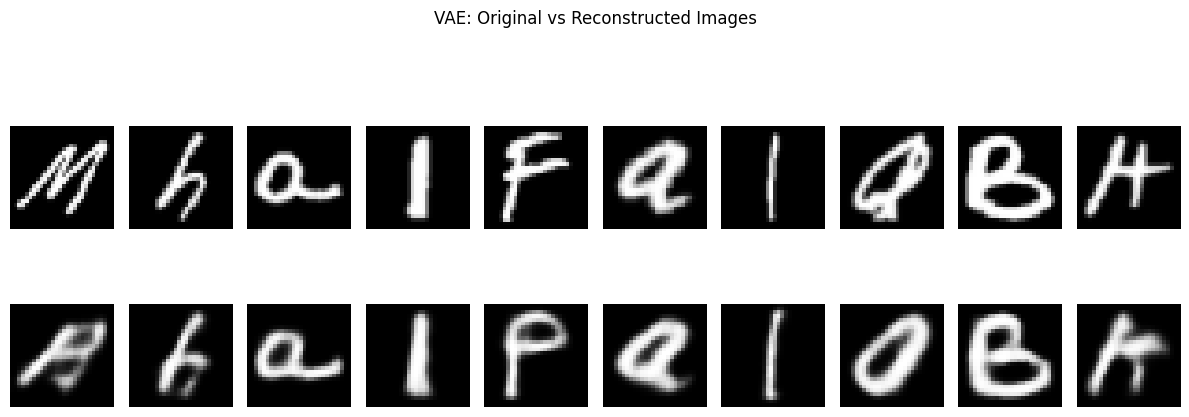

In [22]:
# VAE reconstruction
z_mean_test, z_log_var_test, z_test = vae_encoder.predict(x_test[:10], verbose=0)
vae_reconstructed = vae_decoder.predict(z_test, verbose=0)

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Original", fontsize=10)

    plt.subplot(2, 10, i + 11)
    plt.imshow(vae_reconstructed[i].squeeze(), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("VAE", fontsize=10)

plt.suptitle("VAE: Original vs Reconstructed Images")
plt.tight_layout()
plt.show()

In [23]:
# Evaluate VAE on test data
vae_test_metrics = vae.evaluate(x_test, verbose=0, return_dict=True)

print(f"VAE Test Total Loss        : {vae_test_metrics['loss']:.6f}")
print(f"VAE Test Reconstruction Loss: {vae_test_metrics['reconstruction_loss']:.6f}")
print(f"VAE Test KL Loss           : {vae_test_metrics['kl_loss']:.6f}")

VAE Test Total Loss        : 146.942245
VAE Test Reconstruction Loss: 123.513977
VAE Test KL Loss           : 23.428267


## 11. VAE Image Generation

One of the main advantages of a VAE is that new samples can be generated by sampling latent vectors from a standard normal distribution.

The generated latent vectors are passed through the VAE decoder to produce new letter-like images.

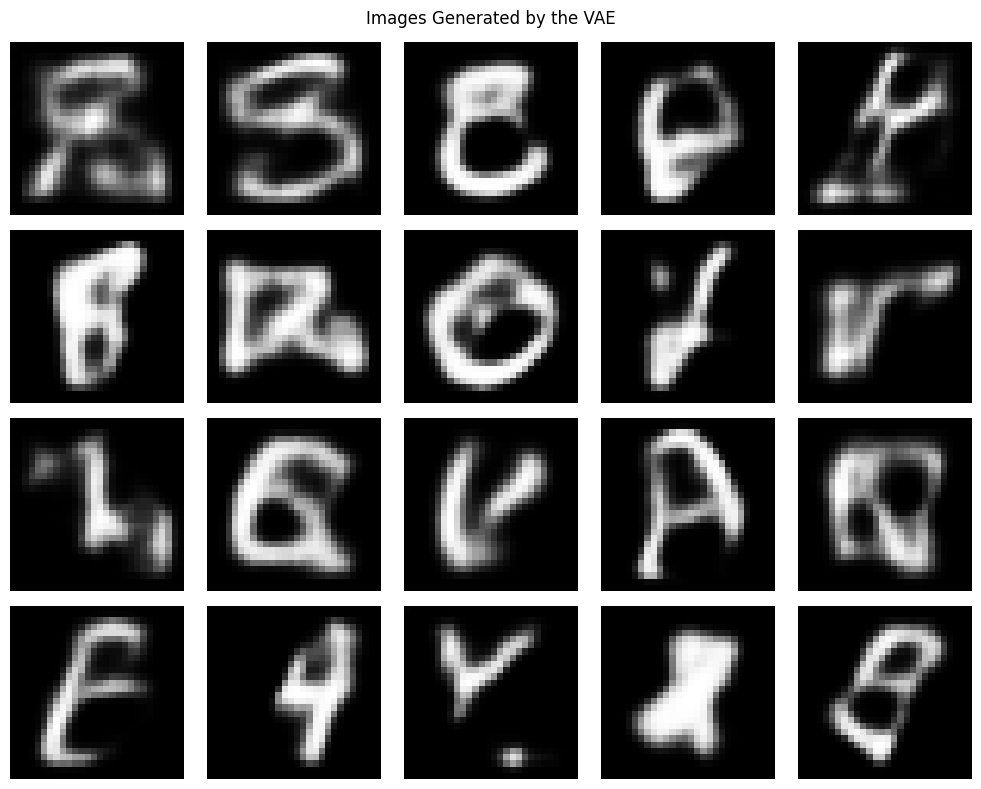

In [24]:
# Generate new images by sampling random points from the VAE latent space
num_generated = 20

random_latent_vectors = np.random.normal(
    size=(num_generated, vae_latent_dim)
).astype("float32")

generated_images = vae_decoder.predict(
    random_latent_vectors,
    verbose=0
)

plt.figure(figsize=(10, 8))

for i in range(num_generated):
    plt.subplot(4, 5, i + 1)
    plt.imshow(generated_images[i].squeeze(), cmap="gray")
    plt.axis("off")

plt.suptitle("Images Generated by the VAE")
plt.tight_layout()
plt.show()

# Part C — Performance Comparison

## 12. Autoencoder vs VAE

### Autoencoder

The standard Autoencoder learns a deterministic mapping from the input image to a latent representation and then reconstructs the image.

### Variational Autoencoder

The VAE learns a probability distribution in the latent space. This makes the latent space more structured and allows random latent vectors to be decoded into new images.


### Comparison Criteria

| Criterion | Autoencoder | VAE |
|---|---|---|
| Image reconstruction | Yes | Yes |
| Latent representation | Deterministic | Probabilistic |
| Training reconstruction loss | Mean Squared Error (MSE) | Binary cross-entropy |
| KL-divergence regularization | No | Yes |
| Random image generation | Not directly supported by a standard AE | Yes |
| Latent-space regularization | No explicit prior constraint | Regularized toward a standard normal distribution |
| Evaluation metric used in this experiment | Test-set MSE | Test-set MSE |


In [25]:

# Quantitative reconstruction comparison using MSE on the same test images

ae_test_recon = autoencoder.predict(
    x_test, batch_size=256, verbose=0
)

# Use the mean latent vector for deterministic VAE reconstruction
z_mean_test, _, _ = vae_encoder.predict(
    x_test, batch_size=256, verbose=0
)

vae_test_recon = vae_decoder.predict(
    z_mean_test, batch_size=256, verbose=0
)

ae_mse = np.mean(np.square(x_test - ae_test_recon))
vae_mse = np.mean(np.square(x_test - vae_test_recon))

print("Quantitative Reconstruction Comparison")
print("--------------------------------------")
print(f"Autoencoder MSE : {ae_mse:.6f}")
print(f"VAE MSE         : {vae_mse:.6f}")

if ae_mse < vae_mse:
    print("Result: Autoencoder has lower reconstruction MSE.")
elif vae_mse < ae_mse:
    print("Result: VAE has lower reconstruction MSE.")
else:
    print("Result: Both models have equal reconstruction MSE.")


Quantitative Reconstruction Comparison
--------------------------------------
Autoencoder MSE : 0.005591
VAE MSE         : 0.014765
Result: Autoencoder has lower reconstruction MSE.


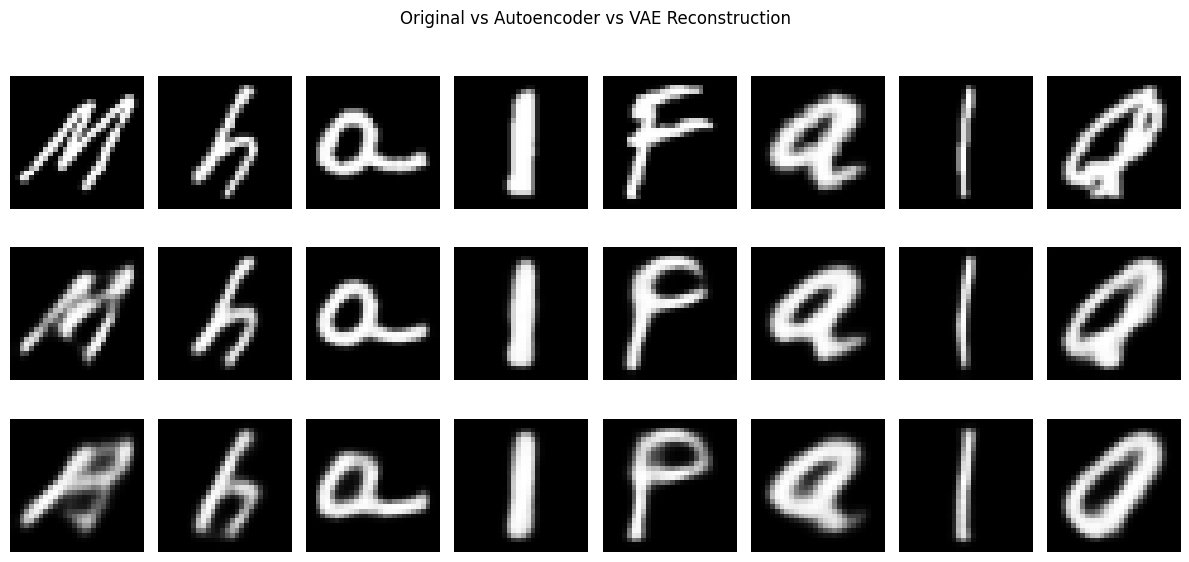

In [26]:
# Side-by-side visual comparison
n = 8

plt.figure(figsize=(12, 6))

for i in range(n):
    plt.subplot(3, n, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Original")

    plt.subplot(3, n, n + i + 1)
    plt.imshow(ae_test_recon[i].squeeze(), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("Autoencoder")

    plt.subplot(3, n, 2 * n + i + 1)
    plt.imshow(vae_test_recon[i].squeeze(), cmap="gray")
    plt.axis("off")
    if i == 0:
        plt.ylabel("VAE")

plt.suptitle("Original vs Autoencoder vs VAE Reconstruction")
plt.tight_layout()
plt.show()

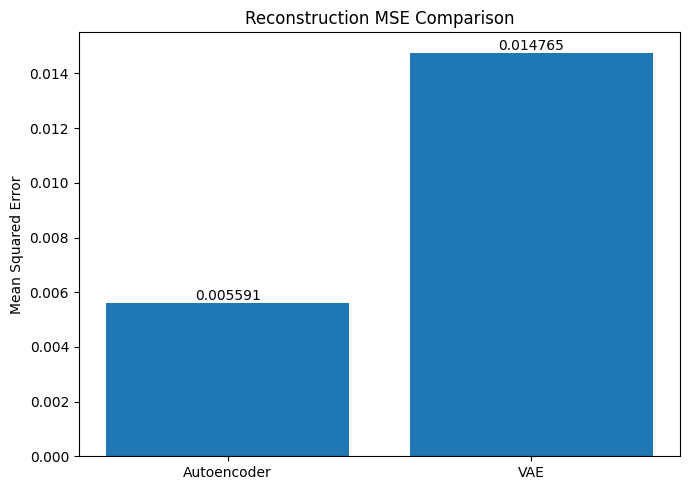

In [27]:
# Bar chart of reconstruction MSE
models = ["Autoencoder", "VAE"]
mse_values = [ae_mse, vae_mse]

plt.figure(figsize=(7, 5))
bars = plt.bar(models, mse_values)
plt.ylabel("Mean Squared Error")
plt.title("Reconstruction MSE Comparison")

for bar, value in zip(bars, mse_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.6f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


## 13. Results and Discussion

### Autoencoder Results

The convolutional Autoencoder learned a compact representation of the EEMNIST Letters handwritten letter images and reconstructed them using its decoder. Its performance was evaluated using Mean Squared Error (MSE), where a lower value indicates a smaller pixel-wise reconstruction error.

### VAE Results

The Variational Autoencoder learned a probabilistic latent representation using the mean, log variance, and reparameterization trick. It reconstructed the input images using a reconstruction loss combined with KL-divergence. Random sampling from its latent space was also used to generate new letter-like images.

### Performance Comparison

Both models were evaluated on the same test images using MSE. The model with the lower MSE produced more accurate pixel-wise reconstructions for this experiment.

The Autoencoder and VAE optimize different training objectives: the Autoencoder uses MSE, while the VAE uses binary cross-entropy reconstruction loss and KL-divergence. Therefore, the common test-set MSE is used for comparing reconstruction quality, while the VAE's total loss is reported separately.

The reconstruction plots provide visual evidence of image quality, and the generated-image grid demonstrates the VAE's ability to produce new samples. Results may vary depending on model initialization and training conditions.



## 14. Conclusion

The Autoencoder and Variational Autoencoder were successfully implemented using the EEEMNIST Letters dataset for image reconstruction. The Autoencoder learned a deterministic latent representation, while the VAE learned a probabilistic latent representation using mean, log variance, and the reparameterization trick.

Both models reconstructed handwritten letter images, and their reconstruction quality was compared using Mean Squared Error (MSE) on the test dataset. The results identify which model achieved lower pixel-wise reconstruction error under the experimental conditions.

The VAE also generated new letter-like images by sampling from its latent space. Thus, the experiment demonstrates that Autoencoders are useful for image reconstruction, while VAEs additionally support probabilistic latent-space learning and image generation.


## 15. Declaration

I, **Shreya Dattaram Bhosale**, confirm that this practical work has been prepared for the Generative AI Lab as part of my academic learning. The notebook demonstrates Autoencoder and Variational Autoencoder implementation using the EMNIST Letters dataset.


**GitHub Repository Link::** https://github.com/bhosaleshreya25/Generative-AI/tree/main/Practical_03

**Signature:** Shreya Dattaram Bhosale
